# 04 — Error analysis and source provenance

This notebook compares Part 2 failure errors using the **same historical Part 1 reason lookup** for the baseline and best outcome model. It retains observed reasons, predicted reasons, training-resubstitution predictions, and unmatched trials separately. This makes a change in outcome prediction distinguishable from a change in how reason groups are defined.

Reasons are retrospective analysis groups, never outcome-model inputs. Multi-reason groups overlap. Small-group rates are descriptive and do not establish causation or generalization.


In [2]:
from pathlib import Path
import sys, os, json, tempfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'models/selection.json').is_file() and (p/'tools/src').is_dir())
for module_dir in (ROOT/'tools/src', ROOT/'report/scripts'):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'midterm-report-mpl'))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code
from midterm_evaluation import REASONS, dataset_path
RUN_TRAINING = False  # Explicit opt-in only. Run All uses saved evidence and does not train.
print('Consolidated project | mode: saved evidence | training:', RUN_TRAINING)


In [3]:
from report_analysis import build_report
report=build_report(ROOT)
display(report['part2_reason_provenance'])
comparison=pd.read_csv(ROOT/'report/analysis/part2_failure_reason_comparison.csv')
comparison=comparison.loc[comparison.reason_group.ne('matched_no_predicted_reason')]
columns=['phase','reason_group','n_trials','n_observed_reasons','n_predicted_reasons',
         'n_training_resubstitution_reasons','n_unmatched','n_predicted_success_baseline',
         'n_predicted_success_best','false_success_rate_baseline','false_success_rate_best','false_success_rate_delta']
display(comparison[columns])


{'lookup_file': 'models/part1/02_kmeans_lr/evidence/selected/reason_lookup.csv',
 'lookup_sha256': '170b9feafeb4118405911c116c226af9b2b7272085d462d695e7610f755aca0a',
 'lookup_rows': 1561,
 'failed_trial_phase_rows': 452,
 'unique_failed_trials': 398,
 'matched_trial_phase_rows': 198,
 'observed_reason_trial_phase_rows': 27,
 'predicted_reason_trial_phase_rows': 171,
 'predicted_training_resubstitution_rows': 131,
 'unmatched_trial_phase_rows': 254,
 'reasons_used_as_predictors': False,
 'reason_model': 'historical KMeans+LR lookup, unchanged for before/after comparison',
 'warning': 'Predicted reasons are model estimates; training resubstitution is not out-of-fold evidence. Multilabel groups overlap. Rates are descriptive, not causal.'}

,phase,reason_group,n_trials,n_observed_reasons,n_predicted_reasons,n_training_resubstitution_reasons,n_unmatched,n_predicted_success_baseline,n_predicted_success_best,false_success_rate_baseline,false_success_rate_best,false_success_rate_delta
0,I,Safety,10,1,9,8,0,4,5,0.400000,0.500000,0.100000
1,I,Funding,4,1,3,3,0,2,2,0.500000,0.500000,0.000000
2,I,Efficacy,5,0,5,4,0,5,5,1.000000,1.000000,0.000000
3,I,Recruitment,22,2,20,15,0,10,7,0.454545,0.318182,-0.136364
4,I,Other,2,0,2,0,0,1,1,0.500000,0.500000,0.000000
5,I,no_recorded_stopping_reason,28,0,0,0,28,17,14,0.607143,0.500000,-0.107143
7,II,Safety,12,1,11,9,0,5,5,0.416667,0.416667,0.000000
8,II,Funding,4,1,3,2,0,0,0,0.000000,0.000000,0.000000
9,II,Efficacy,18,0,18,14,0,4,5,0.222222,0.277778,0.055556
10,II,Recruitment,91,12,79,59,0,17,17,0.186813,0.186813,0.000000


In [4]:
import inspect
from midterm_part2_baseline import analyze_failure_reasons,wilson_interval
display(Code(inspect.getsource(analyze_failure_reasons),language='python'))
source_rates=pd.read_csv(ROOT/'report/analysis/part2_failure_source_rates.csv')
display(source_rates[['model','phase','reason_group','source_type','n_trials','n_predicted_success',
                      'false_success_rate','n_training_resubstitution_reasons']])
display(pd.read_csv(ROOT/'report/analysis/part2_failure_overall_failed_rates.csv'))


def analyze_failure_reasons(validation_predictions, reason_lookup):
    """Compute conditional false-success rates, retaining multilabel and unmatched rows."""
    required = {"ID", "trial_id", "phase", "label", "prediction", "p_success"}
    if not required.issubset(validation_predictions):
        raise ValueError("Provide saved outcome labels, probabilities, and binary decisions.")
    if not validation_predictions["ID"].is_unique or validation_predictions.duplicated(["trial_id", "phase"]).any():
        raise ValueError("Outcome IDs and trial-phase pairs must be unique.")
    if not validation_predictions["label"].isin([0, 1]).all() or not validation_predictions["prediction"].isin([0, 1]).all():
        raise ValueError("Outcome labels and decisions must be binary.")
    scores = validation_predictions["p_success"].to_numpy(dtype=float)
    if not validation_predictions["phase"].isin(PHASES).all() or not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Use known phases and finite success probabilities in [0, 1].")
    lookup_columns = {"ID", *REASONS, "is_observed", "reason_source", "reason_count", "prediction_is_training_resubstitution"}
    if not lookup_columns.issubset(reason_lookup) or not reason_lookup["ID"].is_unique:
        raise ValueError("Use a unique Part 1 lookup with explicit reason provenance.")
    if not reason_lookup[list(REASONS)].isin([0, 1]).all().all() or not reason_lookup["is_observed"].isin([True, False]).all():
        raise ValueError("Lookup reasons must be binary with known observed/predicted status.")
    if not np.array_equal(reason_lookup[list(REASONS)].sum(axis=1), reason_lookup["reason_count"]):
        raise ValueError("Lookup reason counts do not match its label vectors.")
    if (reason_lookup["is_observed"] & reason_lookup["reason_count"].eq(0)).any():
        raise ValueError("Observed Part 1 reason vectors should contain a recorded reason.")
    joined = link_unsuccessful_validation(validation_predictions, reason_lookup)
    joined = joined.merge(validation_predictions[["ID", "p_success", "prediction"]], on="ID", how="left", validate="one_to_one")
    joined["source_type"] = np.where(~joined["matched_part1"], "unmatched",
        np.where(joined["is_observed"].eq(True), "observed", "predicted"))
    joined["incorrectly_predicted_success"] = joined["prediction"].eq(1)
    primary, by_source, source_detail, overall = [], [], [], []
    for phase in PHASES:
        phase_rows = joined.loc[joined["phase"].eq(phase)]
        overall.append(_rate_row(phase_rows, phase, "all_failed_trials"))
        for group in REASON_GROUPS:
            mask = phase_rows[group].eq(1).fillna(False) if group in REASONS else phase_rows["reason_group"].eq(group)
            subset = phase_rows.loc[mask]
            primary.append(_rate_row(subset, phase, group))
            sources = ("unmatched",) if group == "no_recorded_stopping_reason" else ("predicted",) if group == "matched_no_predicted_reason" else ("observed", "predicted")
            for source in sources:
                by_source.append(_rate_row(subset.loc[subset["source_type"].eq(source)], phase, group, source))
            for source, detail in subset.groupby("reason_source", dropna=False):
                row = _rate_row(detail, phase, group)
                row["reason_source"] = source if pd.notna(source) else "no_part1_match"
                source_detail.append(row)
    return {"failed_rows": joined, "reason_rates": pd.DataFrame(primary),
            "source_rates": pd.DataFrame(by_source), "source_detail_rates": pd.DataFrame(source_detail),
            "overall_failed_rates": pd.DataFrame(overall)}

,model,phase,reason_group,source_type,n_trials,n_predicted_success,false_success_rate,n_training_resubstitution_reasons
0,baseline,I,Safety,observed,1,0,0.000000,0
1,baseline,I,Safety,predicted,9,4,0.444444,8
2,baseline,I,Funding,observed,1,0,0.000000,0
3,baseline,I,Funding,predicted,3,2,0.666667,3
4,baseline,I,Efficacy,observed,0,0,NaN,0
...,...,...,...,...,...,...,...,...
67,phase_shared_best,III,Recruitment,predicted,18,12,0.666667,14
68,phase_shared_best,III,Other,observed,2,2,1.000000,0
69,phase_shared_best,III,Other,predicted,4,3,0.750000,2
70,phase_shared_best,III,no_recorded_stopping_reason,unmatched,82,50,0.609756,0


,phase,reason_group,source_type,n_trials,n_predicted_success,false_success_rate,wilson_95_lower,wilson_95_upper,n_observed_reasons,n_predicted_reasons,n_unmatched,n_training_resubstitution_reasons,label_evidence,small_support,rate_status,model
0,I,all_failed_trials,all,64,34,0.531250,0.410721,0.648240,4,32,28,25,mixed,False,ok,baseline
1,II,all_failed_trials,all,265,73,0.275472,0.225181,0.332179,16,105,144,78,mixed,False,ok,baseline
2,III,all_failed_trials,all,123,80,0.650407,0.562743,0.728960,7,34,82,28,mixed,False,ok,baseline
3,I,all_failed_trials,all,64,29,0.453125,0.337294,0.574264,4,32,28,25,mixed,False,ok,phase_shared_best
4,II,all_failed_trials,all,265,73,0.275472,0.225181,0.332179,16,105,144,78,mixed,False,ok,phase_shared_best
5,III,all_failed_trials,all,123,78,0.634146,0.546162,0.714006,7,34,82,28,mixed,False,ok,phase_shared_best


## Figure code and retained before/after heatmap

The color range is fixed at 0–1 for both outcome models. Each cell reports its denominator; a group with zero trials is `NA`, not a zero error rate. Wilson intervals in the CSV tables quantify binomial sampling uncertainty only and omit uncertainty in predicted reason labels.


def make_figures(root):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    out = root / 'report/analysis'
    figures = root / 'report/figures'
    figures.mkdir(parents=True, exist_ok=True)
    p1 = pd.read_csv(out/'part1_validation_by_reason.csv')
    shown = ['supervised_lr', 'retained_kmeans_lr', 'fixed_ridge_157_gold']
    matrix = p1.pivot(index='reason', columns='model', values='f1').reindex(REASONS)[shown]
    ax = matrix.rename(columns={'supervised_lr':'Supervised LR', 'retained_kmeans_lr':'K-Means + LR', 'fixed_ridge_157_gold':'Fixed RBF ridge'}).plot.bar(figsize=(9,4.5), ylim=(0,1), rot=0)
    ax.set_ylabel('Validation F1 per reason'); ax.set_xlabel(''); ax.set_title('Part 1: same nonempty output policy, 78 validation trials',pad=35)
    ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=3,frameon=False); ax.figure.tight_layout(); ax.figure.savefig(figures/'part1_reason_f1.png', dpi=160); plt.close(ax.figure)
    p2 = pd.read_csv(out/'part2_validation_by_phase.csv')
    matrix = p2.pivot(index='phase', columns='model', values='log_loss').reindex(['I','II','III'])
    ax = matrix.rename(columns={'baseline':'TF-IDF baseline','phase_shared_best':'Phase-shared blend'}).plot.bar(figsize=(7.5,4.3), rot=0)
    ax.set_ylabel('Validation log loss (lower is better)'); ax.set_xlabel('Phase'); ax.set_title('Part 2: saved validation probabilities',pad=35)
    ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=2,frameon=False)
    ax.figure.tight_layout(); ax.figure.savefig(figures/'part2_phase_logloss.png', dpi=160); plt.close(ax.figure)
    comparison = pd.read_csv(out/'part2_failure_reason_comparison.csv')
    reason_order = [*REASONS, 'no_recorded_stopping_reason']
    labels = [*REASONS, 'No Part 1 match']
    fig, axes = plt.subplots(1,2,figsize=(11.8,4.5),sharey=True)
    for ax, suffix, title in zip(axes, ['baseline','best'], ['TF-IDF baseline','Phase-shared blend']):
        selected = comparison[comparison.reason_group.isin(reason_order)]
        rates = selected.pivot(index='reason_group',columns='phase',values='false_success_rate_'+suffix).reindex(reason_order)[['I','II','III']]
        counts = selected.pivot(index='reason_group',columns='phase',values='n_trials').reindex(reason_order)[['I','II','III']]
        image = ax.imshow(rates.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
        for i in range(len(reason_order)):
            for j in range(3):
                value, count = rates.iloc[i,j], int(counts.iloc[i,j])
                text = 'NA (n=0)' if pd.isna(value) else f'{value:.2f}\n(n={count})'
                ax.text(j,i,text,ha='center',va='center',fontsize=9,color='white' if value>.6 else 'black')
        ax.set_xticks(range(3), ['I','II','III']); ax.set_yticks(range(6), labels); ax.set_title(title); ax.set_xlabel('Phase')
    fig.suptitle('False-success rate among failed validation trials; historical reason groups')
    fig.subplots_adjust(left=.18,right=.88,top=.84,bottom=.12,wspace=.12)
    fig.colorbar(image,ax=axes,location='right',fraction=.035,pad=.035,label='False-success rate')
    fig.savefig(figures/'part2_failure_reason_comparison.png',dpi=160); plt.close(fig)
    return sorted(str(p.relative_to(root)) for p in figures.glob('*.png'))

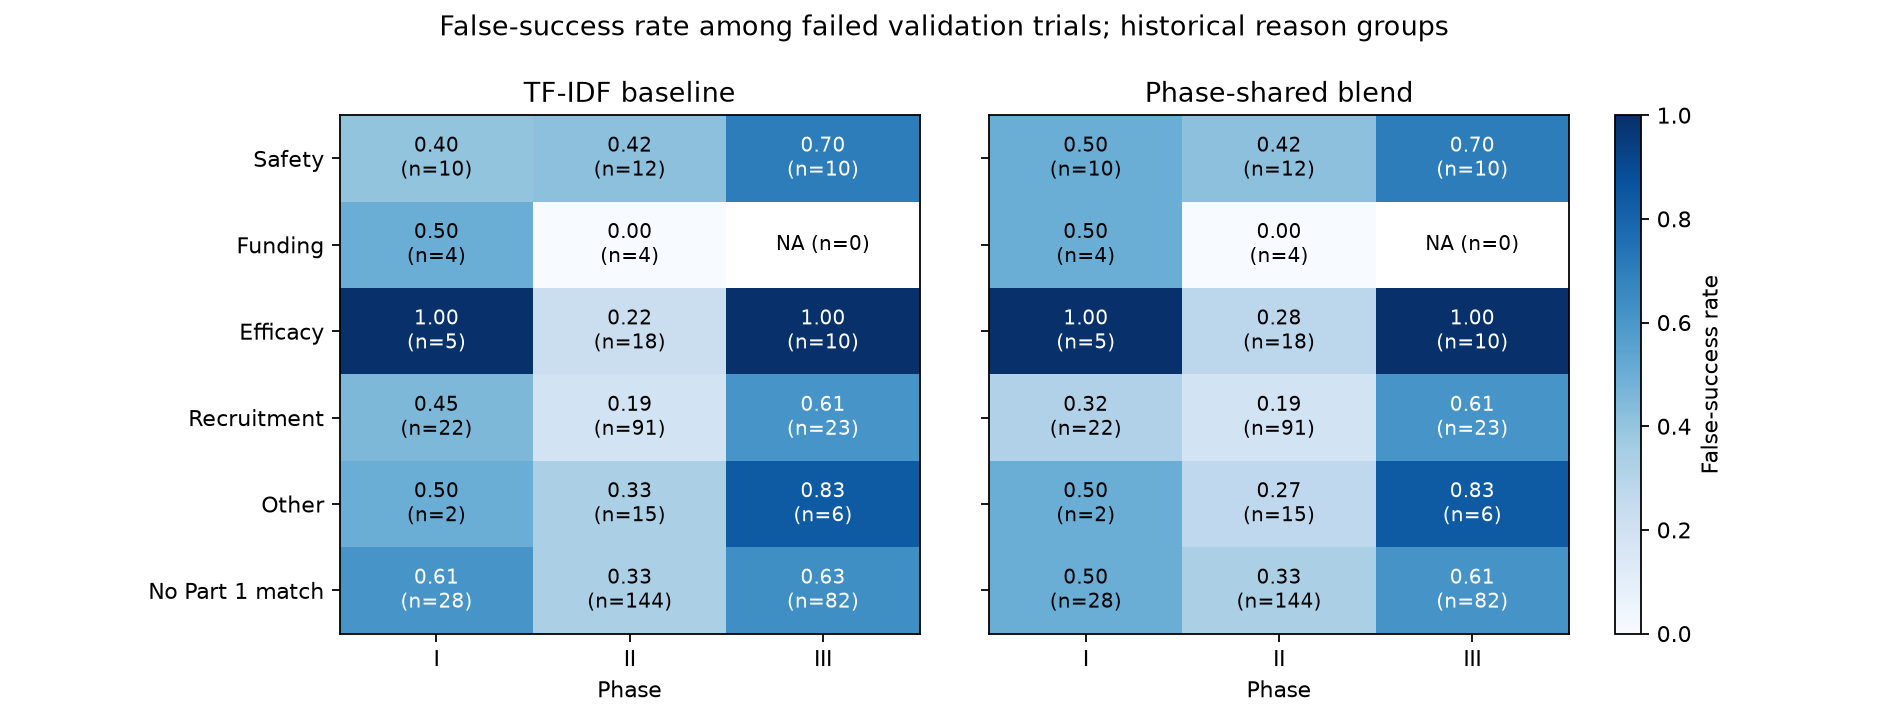

In [5]:
from report_analysis import make_figures
display(Code(inspect.getsource(make_figures),language='python'))
display(Image(filename=str(ROOT/'report/figures/part2_failure_reason_comparison.png')))


In [6]:
predictions=pd.read_csv(ROOT/'report/analysis/part1_validation_predictions.csv')
ridge=predictions.loc[predictions.model.eq('fixed_ridge_157_gold')].copy()
truth=ridge[['true_'+r for r in REASONS]].to_numpy()
pred=ridge[['pred_'+r for r in REASONS]].to_numpy()
ridge['truth_set']=[' '.join(r for r,v in zip(REASONS,row) if v) for row in truth]
ridge['predicted_set']=[' '.join(r for r,v in zip(REASONS,row) if v) for row in pred]
display(ridge.loc[(truth!=pred).any(axis=1),['ID','truth_set','predicted_set',*['prob_'+r for r in REASONS]]])
print('This is the saved train157 validation fit, not a resubstitution audit of the final235-label model.')


,ID,truth_set,predicted_set,prob_Safety,prob_Funding,prob_Efficacy,prob_Recruitment,prob_Other
236,TR11226,Other,Recruitment,0.025338,0.000581,0.169342,0.333179,0.098830
237,TR01691,Efficacy,Other,0.001012,0.004198,0.311604,0.304118,0.518732
241,TR10050,Other,Efficacy,0.221484,0.000405,0.558666,0.022151,0.429136
251,TR04350,Efficacy,Recruitment,0.007682,0.003293,0.163109,0.663621,0.053328
253,TR09519,Recruitment Other,Recruitment,0.014647,0.001102,0.080535,0.629464,0.152396
258,TR09218,Safety Efficacy,Efficacy,0.191291,0.000194,0.431173,0.087513,0.153540
272,TR08905,Safety Efficacy,Safety,0.709196,0.000189,0.218679,0.062915,0.221602
274,TR07268,Safety Efficacy,Safety,0.922973,0.006068,0.195560,0.099115,0.036173
275,TR03536,Recruitment Other,Recruitment,0.002920,0.002663,0.048480,0.881572,0.070179
277,TR03061,Funding,Funding Other,0.013311,0.689397,0.033924,0.021847,0.544507


## Negative experiments and stopping rule

The local-ensemble/Other-kernel/expected-F1 follow-up and the ridge-boundary/group-weight study were bounded, nested comparisons against the fixed 0.88568 recipe. Neither authorized a replacement submission. Their saved summaries below preserve that negative evidence; no new search is performed here. Historical diagnostics and repeated OOF must not be presented as independent fresh tests.


In [7]:
records=[]
for name in ('local_followup','ridge_boundary'):
    result=json.loads((ROOT/f'models/part1/exploration/{name}/summary.json').read_text())
    records.append({'study':name,'baseline_OOF':result['overall']['baseline']['sample_f1'],
                    'candidate_procedure_OOF':result['overall']['final']['sample_f1'],
                    'candidate_allowed':result['candidate_allowed'], 'candidate':result['candidate']})
display(pd.DataFrame(records))
print('The report keeps the public-best ridge and phase-shared blend. No model is trained or promoted by this notebook.')


,study,baseline_OOF,candidate_procedure_OOF,candidate_allowed,candidate
0,local_followup,0.9026,0.900236,False,None
1,ridge_boundary,0.9026,0.898345,False,None
